In [2]:

%pip install -q langchain-text-splitters pypdf openai tiktoken sentence-transformers matplotlib pandas python-dotenv


Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, re, json, statistics
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pypdf import PdfReader

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter,
)

In [13]:
load_dotenv()   # reads the .env file

if os.getenv("OPENAI_API_KEY"):
    print("API key found")
else:
    print("No API key found. Check your .env file (it is needed for transcription).")

API key found


In [14]:
AUDIO_PATH = Path("The_Blueprint_For_Trustworthy_AI.m4a")

print("Current working folder:", Path.cwd())
if AUDIO_PATH.exists():
    print(f"Audio found: {AUDIO_PATH.name} ({AUDIO_PATH.stat().st_size / 1_000_000:.1f} MB)")
else:
    print("Audio NOT FOUND. Move the file into the folder shown above.")

Current working folder: /Users/elifyurdakul/Downloads/W3D2/RAGWORK/lab-chunking-strategies
Audio found: The_Blueprint_For_Trustworthy_AI.m4a (30.2 MB)


In [5]:
import subprocess, glob

TRANSCRIPT_PATH = Path("transcript.txt")

def transcribe_audio(audio_path, out_path, model="whisper-1", piece_seconds=600):
    """Transcribe audio with the OpenAI API and save the text. Skips all work if out_path already exists."""
    out = Path(out_path)
    if out.exists() and out.stat().st_size > 0:
        print(f"{out} already exists -> skipping transcription")
        return out.read_text(encoding="utf-8")

    # 1) shrink and cut the audio: mono, 64 kbps mp3, 10-minute pieces
    Path("_pieces").mkdir(exist_ok=True)
    subprocess.run(["ffmpeg", "-v", "error", "-y", "-i", str(audio_path), "-ac", "1", "-b:a", "64k",
                    "-f", "segment", "-segment_time", str(piece_seconds), "-reset_timestamps", "1",
                    "_pieces/piece_%02d.mp3"], check=True)

    # 2) transcribe the pieces in order
    from openai import OpenAI
    client = OpenAI()                                  # uses OPENAI_API_KEY from the environment
    texts = []
    for f in sorted(glob.glob("_pieces/piece_*.mp3")):
        with open(f, "rb") as fh:
            texts.append(client.audio.transcriptions.create(model=model, file=fh).text)
        print(f, "done")

    text = " ".join(texts)
    out.write_text(text, encoding="utf-8")             # save to a local file
    return text

podcast_text = transcribe_audio(AUDIO_PATH, TRANSCRIPT_PATH)
print(f"Podcast transcript length: {len(podcast_text)} chars")
print(podcast_text[:200])

_pieces/piece_00.mp3 done
_pieces/piece_01.mp3 done
Podcast transcript length: 16461 chars
So imagine for a second you're driving across, I don't know, a massive suspension bridge. OK. You don't pull over halfway across, get out and demand to see the blueprints, right? You don't interview t


In [17]:
PDF_PATH = Path("ai_hleg_ethics_guidelines_for_trustworthy_ai-en.pdf")

def load_pdf(path=PDF_PATH):
    reader = PdfReader(path)
    return "\n".join(page.extract_text() or "" for page in reader.pages)

pdf_text = load_pdf()
print(f"PDF length: {len(pdf_text)} chars")
print(pdf_text[:200])

PDF length: 156411 chars
 
 
 
 
 
 
INDEPENDENT 
HIGH-LEVEL EXPERT GROUP ON 
ARTIFICIAL INTELLIGENCE 
SET UP BY THE EUROPEAN COMMISSION 
 
 
 
 
 
 
ETHICS GUIDELINES 
FOR TRUSTWORTHY AI 
 
 
 
 
 
 
ETHICS GUIDELINES FOR TR


In [18]:
print("PDF paragraph breaks:    ", pdf_text.count("\n\n"))
print("Podcast paragraph breaks:", podcast_text.count("\n\n"))
print("PDF line breaks:         ", pdf_text.count("\n"))
print("Podcast line breaks:     ", podcast_text.count("\n"))

PDF paragraph breaks:     3
Podcast paragraph breaks: 0
PDF line breaks:          1961
Podcast line breaks:      0


In [20]:
def chunk_stats(chunks, name):
    """Return the key numbers for a list of text chunks."""
    sizes = [len(c) for c in chunks]
    clean = sum(1 for c in chunks if c.strip() and c.strip()[-1] in ".?!")
    return {
        "strategy": name,
        "chunks": len(chunks),
        "avg": round(statistics.mean(sizes)),
        "min": min(sizes),
        "max": max(sizes),
        "clean_end_%": round(clean / len(chunks) * 100, 1),
    }

In [21]:
rows = []
for text, source in [(pdf_text, "PDF"), (podcast_text, "Podcast")]:
    for size in [500, 1000, 2000]:
        for overlap in [0, 50, 100]:
            splitter = CharacterTextSplitter(separator="", chunk_size=size, chunk_overlap=overlap)
            chunks = splitter.split_text(text)
            row = chunk_stats(chunks, f"Fixed-{size}/ov{overlap}")
            row["source"] = source
            rows.append(row)

fixed_df = pd.DataFrame(rows)
fixed_df

,strategy,chunks,avg,min,max,clean_end_%,source
0,Fixed-500/ov0,313,498,382,500,2.2,PDF
1,Fixed-500/ov50,348,498,258,500,3.2,PDF
2,Fixed-500/ov100,391,499,408,500,3.3,PDF
3,Fixed-1000/ov0,157,995,408,1000,3.2,PDF
4,Fixed-1000/ov50,165,995,608,1000,3.6,PDF
5,Fixed-1000/ov100,174,997,708,1000,1.7,PDF
6,Fixed-2000/ov0,79,1979,408,2000,3.8,PDF
7,Fixed-2000/ov50,81,1976,408,2000,6.2,PDF
8,Fixed-2000/ov100,83,1982,608,2000,1.2,PDF
9,Fixed-500/ov0,33,498,460,500,15.2,Podcast


In [22]:
splitter = CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=0)
pdf_fixed = splitter.split_text(pdf_text)
for c in pdf_fixed[10:13]:
    print("...END:", repr(c[-60:]))

...END: ' to individuals and society, AI systems also pose \ncertain r'
...END: 'n \nrequirements that AI systems should meet . Both technical'
...END: 'and (7) accountability.  \n\uf0fc Consider technical and non-techn'


In [23]:
for text, source in [(pdf_text, "PDF"), (podcast_text, "Podcast")]:
    splitter = CharacterTextSplitter(separator="\n\n", chunk_size=1000, chunk_overlap=0)
    chunks = splitter.split_text(text)
    stats = chunk_stats(chunks, "Fixed-1000 sep=\\n\\n")
    stats["too_big"] = sum(1 for c in chunks if len(c) > 1000)
    print(source, stats)

Created a chunk of size 28061, which is longer than the specified 1000
Created a chunk of size 29967, which is longer than the specified 1000
Created a chunk of size 23694, which is longer than the specified 1000


PDF {'strategy': 'Fixed-1000 sep=\\n\\n', 'chunks': 4, 'avg': 39093, 'min': 23693, 'max': 74680, 'clean_end_%': 50.0, 'too_big': 4}
Podcast {'strategy': 'Fixed-1000 sep=\\n\\n', 'chunks': 1, 'avg': 16461, 'min': 16461, 'max': 16461, 'clean_end_%': 100.0, 'too_big': 1}


In [24]:
SEPARATORS = ["\n\n", "\n", ". ", " ", ""]

rec_rows = []
for text, source in [(pdf_text, "PDF"), (podcast_text, "Podcast")]:
    for size in [500, 1000, 2000]:
        splitter = RecursiveCharacterTextSplitter(
            chunk_size=size, chunk_overlap=100, separators=SEPARATORS)
        row = chunk_stats(splitter.split_text(text), f"Recursive-{size}")
        row["source"] = source
        rec_rows.append(row)

rec_df = pd.DataFrame(rec_rows)
rec_df

,strategy,chunks,avg,min,max,clean_end_%,source
0,Recursive-500,364,444,175,498,24.7,PDF
1,Recursive-1000,170,933,229,998,21.8,PDF
2,Recursive-2000,83,1896,363,1995,20.5,PDF
3,Recursive-500,42,457,191,498,2.4,Podcast
4,Recursive-1000,19,929,191,997,5.3,Podcast
5,Recursive-2000,9,1877,1120,2000,11.1,Podcast


In [25]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=0, separators=SEPARATORS)
pod_rec = splitter.split_text(podcast_text)
for c in pod_rec[3:6]:
    print("START:", repr(c[:30]), "| END:", repr(c[-30:]))

START: '. So why are we blowing the du' | END: 't just talking philosophy here'
START: ". We're looking at how you tak" | END: 'the system. Not just at launch'
START: '. Not just at launch. From des' | END: 't laws are slow. Terribly slow'


In [26]:
rec_rows = []
for text, source in [(pdf_text, "PDF"), (podcast_text, "Podcast")]:
    for size in [500, 1000, 2000]:
        splitter = RecursiveCharacterTextSplitter(
            chunk_size=size, chunk_overlap=100,
            separators=SEPARATORS, keep_separator="end")
        row = chunk_stats(splitter.split_text(text), f"Recursive-{size}")
        row["source"] = source
        rec_rows.append(row)
rec_df = pd.DataFrame(rec_rows)
rec_df

,strategy,chunks,avg,min,max,clean_end_%,source
0,Recursive-500,364,444,175,498,24.7,PDF
1,Recursive-1000,170,933,229,998,21.8,PDF
2,Recursive-2000,83,1896,363,1995,20.5,PDF
3,Recursive-500,42,456,189,497,100.0,Podcast
4,Recursive-1000,19,929,189,996,100.0,Podcast
5,Recursive-2000,9,1876,1118,1999,100.0,Podcast


In [27]:
# A) Sentences before lines
sep_sentence_first = ["\n\n", ". ", "\n", " ", ""]

# B) Repair the text first: turn single line-wraps into spaces, keep paragraph breaks
pdf_clean = re.sub(r"(?<!\n)\n(?!\n)", " ", pdf_text)

tests = [
    ("PDF original, default order", pdf_text, SEPARATORS),
    ("PDF original, sentences first", pdf_text, sep_sentence_first),
    ("PDF cleaned, default order", pdf_clean, SEPARATORS),
]
rows = []
for name, text, seps in tests:
    splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100,
                                              separators=seps, keep_separator="end")
    rows.append(chunk_stats(splitter.split_text(text), name))
pd.DataFrame(rows)

,strategy,chunks,avg,min,max,clean_end_%
0,"PDF original, default order",170,933,229,998,21.8
1,"PDF original, sentences first",185,863,157,997,95.7
2,"PDF cleaned, default order",185,867,157,999,91.4


In [28]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100,
                                          separators=sep_sentence_first, keep_separator="end")
print(chunk_stats(splitter.split_text(pdf_clean), "PDF cleaned + sentences first"))

{'strategy': 'PDF cleaned + sentences first', 'chunks': 185, 'avg': 867, 'min': 157, 'max': 999, 'clean_end_%': 91.4}


In [30]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100,
                                          separators=sep_sentence_first, keep_separator="end")
pdf_rec = splitter.split_text(pdf_clean)
bad = [c for c in pdf_rec if c.strip()[-1] not in ".?!"]
for c in bad[:3]:
    print("END:", repr(c[-80:]))

END: 'thical AI).    8      Figure 1: The Guidelines as a framework for Trustworthy AI'
END: 'hers. Moreover, mechanisms should be put into place to receive external feedback'
END: 't:  \uf0fc Did you consider the appropriate level of human control for the particular'


In [29]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")

tok_rows = []
for text, source in [(pdf_clean, "PDF"), (podcast_text, "Podcast")]:
    for size in [300, 500, 1000]:
        splitter = TokenTextSplitter(encoding_name="cl100k_base", chunk_size=size, chunk_overlap=50)
        chunks = splitter.split_text(text)
        row = chunk_stats(chunks, f"Token-{size}")
        row["avg_tokens"] = round(statistics.mean(len(enc.encode(c)) for c in chunks))
        row["source"] = source
        tok_rows.append(row)
pd.DataFrame(tok_rows)

,strategy,chunks,avg,min,max,clean_end_%,avg_tokens,source
0,Token-300,125,1500,1077,1780,8.0,300,PDF
1,Token-500,70,2477,893,2890,5.7,496,PDF
2,Token-1000,33,4987,3560,5453,12.1,997,PDF
3,Token-300,14,1389,1102,1506,14.3,297,Podcast
4,Token-500,8,2267,1576,2499,25.0,482,Podcast
5,Token-1000,4,4312,3142,4840,50.0,915,Podcast


In [31]:
splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base", chunk_size=300, chunk_overlap=50,
    separators=sep_sentence_first, keep_separator="end")
print(chunk_stats(splitter.split_text(pdf_clean), "Recursive-token-300 (PDF)"))

{'strategy': 'Recursive-token-300 (PDF)', 'chunks': 147, 'avg': 1189, 'min': 218, 'max': 1769, 'clean_end_%': 83.0}


In [32]:
compare = []
for text, source in [(pdf_clean, "PDF"), (podcast_text, "Podcast")]:
    strategies = {
        "Fixed-500": CharacterTextSplitter(separator="", chunk_size=500, chunk_overlap=50),
        "Recursive-1000": RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100,
                              separators=sep_sentence_first, keep_separator="end"),
        "Token-500": TokenTextSplitter(encoding_name="cl100k_base", chunk_size=500, chunk_overlap=50),
    }
    for name, splitter in strategies.items():
        row = chunk_stats(splitter.split_text(text), name)
        row["source"] = source
        compare.append(row)
compare_df = pd.DataFrame(compare)
compare_df

,strategy,chunks,avg,min,max,clean_end_%,source
0,Fixed-500,348,498,258,500,3.2,PDF
1,Recursive-1000,185,867,157,999,91.4,PDF
2,Token-500,70,2477,893,2890,5.7,PDF
3,Fixed-500,37,493,261,500,8.1,Podcast
4,Recursive-1000,19,929,189,996,100.0,Podcast
5,Token-500,8,2267,1576,2499,25.0,Podcast


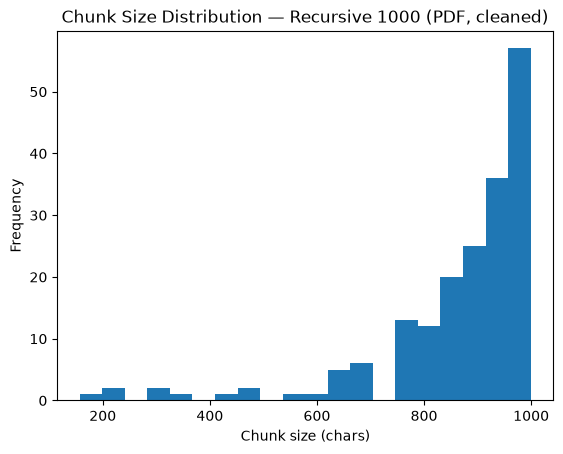

In [33]:
sizes = [len(c) for c in pdf_rec]
plt.hist(sizes, bins=20)
plt.xlabel("Chunk size (chars)"); plt.ylabel("Frequency")
plt.title("Chunk Size Distribution — Recursive 1000 (PDF, cleaned)")
plt.show()

In [34]:
from openai import OpenAI
import numpy as np
client = OpenAI()

def embed(texts):
    resp = client.embeddings.create(model="text-embedding-3-small", input=texts)
    return np.array([d.embedding for d in resp.data])

chunk_vectors = embed(pdf_rec)                      # pdf_rec = recursive, cleaned PDF chunks

query = "What are the seven key requirements for trustworthy AI?"
q = embed([query])[0]
scores = chunk_vectors @ q / (np.linalg.norm(chunk_vectors, axis=1) * np.linalg.norm(q))
top = scores.argsort()[::-1][:3]

for i in top:
    print(f"\n--- chunk {i} | similarity {scores[i]:.3f} ---\n{pdf_rec[i][:400]}")


--- chunk 110 | similarity 0.777 ---
24    Key guidance derived from Chapter II:   Ensure that the AI system’s entire life cycle meets the seven key requirements for Trustworthy AI: (1)  human agency and oversight, (2) technical robustness and safety, (3) privacy and data g overnance, (4)  transparency, (5) diversity, non-discrimination and fairness, (6) environmental and s ocietal well-being and  (7) accountability.    Consider te

--- chunk 7 | similarity 0.735 ---
II. Drawing upon Chapter I , Chapter II provides guidance on how Trustworthy AI can be realised, by listing seven  requirements that AI systems should meet . Both technical and non -technical methods can be used for their  implementation.   Key guidance derived from Chapter II:   Ensure that the development, deployment and use of AI systems meets the seven key requirements for  Trustworthy AI: (1

--- chunk 111 | similarity 0.707 ---
Be transparent about the fact that they are dealing with an AI system.   Facilitate t

In [36]:
context = "\n\n".join(f"[chunk {i}] {pdf_rec[i]}" for i in top)
answer = client.chat.completions.create(
    model="gpt-4o-mini", temperature=0,
    messages=[{"role": "user", "content":
        f"Answer using ONLY the context below. Cite chunk numbers. "
        f"If the answer is not in the context, say so.\n\n{context}\n\nQuestion: {query}"}]
).choices[0].message.content
print(answer)

The seven key requirements for Trustworthy AI are: (1) human agency and oversight, (2) technical robustness and safety, (3) privacy and data governance, (4) transparency, (5) diversity, non-discrimination and fairness, (6) environmental and societal well-being, and (7) accountability (chunks 110 and 7).


In [37]:
requirements = ["human agency", "robustness", "privacy", "transparency",
                "diversity", "well-being", "accountability"]
for i in top:
    found = [r for r in requirements if r in pdf_rec[i].lower()]
    print(f"chunk {i}: {len(found)}/7 → {found}")

chunk 110: 7/7 → ['human agency', 'robustness', 'privacy', 'transparency', 'diversity', 'well-being', 'accountability']
chunk 7: 7/7 → ['human agency', 'robustness', 'privacy', 'transparency', 'diversity', 'well-being', 'accountability']
chunk 111: 0/7 → []
